# CCE 3206 - Digital Signal Processing 
## Practical 3: Frequency response of an FIR filter 
### Name: Dave Galea
### ID: 0283404L

# Task 1 

In [1]:
import numpy as np 

h = np.array([-0.0147, 0.173, 0.342, 0.342, 0.173, -0.0147])
def filter(x):
    # set y to have the same length and type as x 
    y = np.zeros_like(x, dtype = float)

    # iterate overall all input samples
    for n in range(len(x)): # x array is in memory 
        # calculate y_n and store it in y[n]
        y_n = 0
        for k in range(6):
            if (n-k) < 0: # dont try access beyond what x holds
                y_n += 0
            elif (n-k) >= 0:
                y_n += h[k] * x[n-k]

        y[n] = y_n

    return y



# Task 2 

### a) 

In [2]:
x = np.zeros(10)
x[0] = 1

### b)

In [3]:
y = filter(x)

### c)

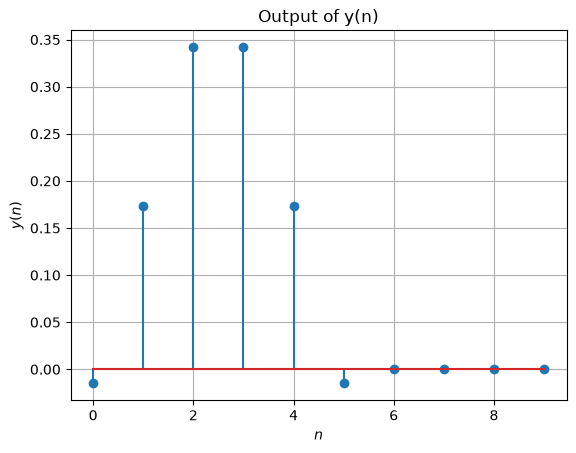

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
n = np.arange(len(y))
ax.stem(n, y)
ax.set_xlabel('$n$')
ax.set_ylabel('$y(n)$')
plt.grid()
plt.title("Output of y(n)")
plt.show()

# Task 3 


In [5]:
for n in range(len(h)) :
    if y[n] == h[n]:
        print ("h(n) and y(n) match for n = ", n)
    elif y[n] != h[n]:
        print ("h(n) and y(n) do not match for n = ",n)

for n in range(len(h), len(y)):
    if y[n] == 0:
        print("y(n) is zero for n =", n)
    elif y[n] != 0:
        print("y(n) is not zero for n =", n)

h(n) and y(n) match for n =  0
h(n) and y(n) match for n =  1
h(n) and y(n) match for n =  2
h(n) and y(n) match for n =  3
h(n) and y(n) match for n =  4
h(n) and y(n) match for n =  5
y(n) is zero for n = 6
y(n) is zero for n = 7
y(n) is zero for n = 8
y(n) is zero for n = 9


As seen above, the output y(n) of the filter when the input is the unit impulse x(n) is equal to h(n) 

# Task 4 

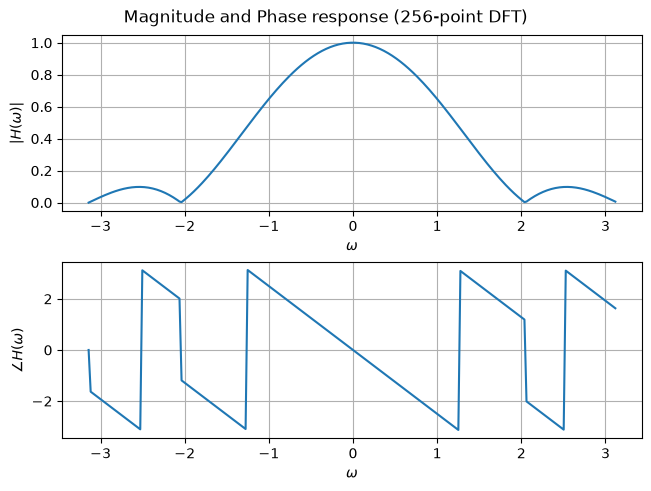

In [6]:
from scipy.fft import fft, fftfreq, fftshift

# use a 256-point DFT
H = fft(h, 256)
# frequencies w corresponding to the output of fft
w = fftfreq(256) * 2 * np.pi
# shift so that w = 0 is at the center
H = fftshift(H)
w = fftshift(w)

fig, ax = plt.subplots(2,1, constrained_layout = True)
fig.suptitle("Magnitude and Phase response (256-point DFT)")

ax[0].plot(w, abs(H)) # -> magnitude reponse 
ax[0].set_xlabel('$\\omega$')
ax[0].set_ylabel('$|H(\\omega)|$')
ax[0].grid(True)

# similarly plot angle of H(w) using np.angle(H)
ax[1].plot(w, np.angle(H)) # -> phase reponse
ax[1].set_xlabel('$\\omega$')
ax[1].set_ylabel('$\\angle H(\\omega)$')
ax[1].grid(True)

plt.show()

# Task 5 

### a)

From the magnitude response graph one can note that higher attenuation happens for higher frequency components, while lower frequency components, around the area $\omega$ = 0, have the least attenuation. The filter is therefore a **low-pass** filter.

### b)

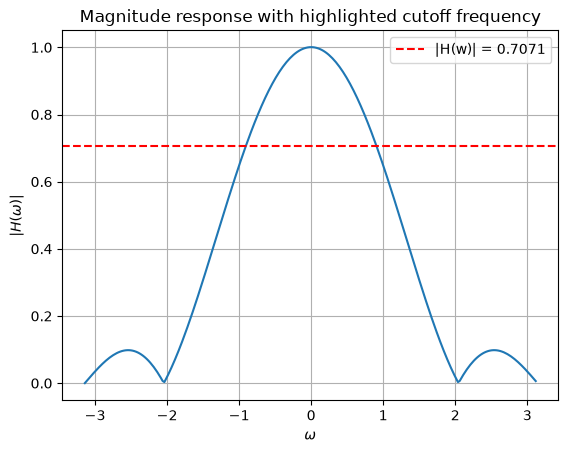

Cutoff frequency is ± 0.9081166264282996 rad/sample


In [7]:
plt.plot(w, abs(H))
plt.xlabel('$\\omega$')
plt.ylabel('$|H(\\omega)|$')
plt.axhline(y = 0.7071, linestyle='--', color='red',  label = "|H(w)| = 0.7071")
plt.grid(True)
plt.title("Magnitude response with highlighted cutoff frequency")
plt.legend()
plt.show()

# find it with code 
for i in range(len(H)):
    if abs((abs(H[i]) - 0.7071)) < 0.01 and w[i] > 0:
        print(f"Cutoff frequency is \u00B1 {w[i]} rad/sample")

### c)

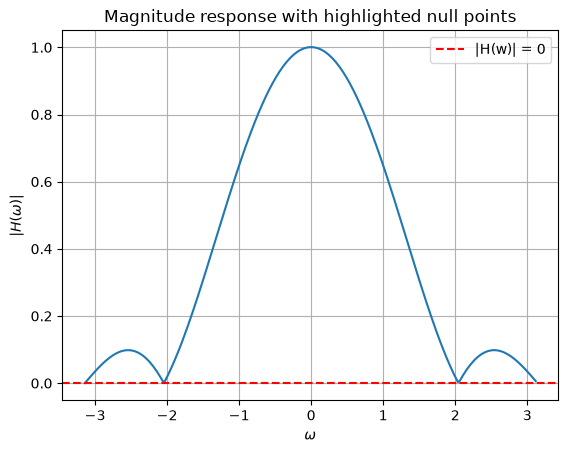

In [8]:
plt.plot(w, abs(H))
plt.xlabel('$\\omega$')
plt.ylabel('$|H(\\omega)|$')
plt.axhline(y = 0, linestyle='--', color='red', label = "|H(w)| = 0")
plt.grid(True)
plt.title("Magnitude response with highlighted null points")
plt.legend()
plt.show()

# for i in range(len(H)):
#     if abs(H[i]) < 0.01 and w[i] > 0:
#         print(f"Null points are \u00B1 {w[i]} rad/sample")

# issue with the above explained below 


The above code **erroneously** gave the following: 

- Null points are ± 2.0371264863121317 rad/sample
- Null points are ± 2.061670178918302 rad/sample
- Null points are ± 3.117048960983623 rad/sample

Upon further inspection in the graph below it was clear why this error occured:

The frequency resolution of the DFT was not high enough to capture all possible frequencies, and therefore, when applying the abs(H[i]) < 0.01 condition, the frequency points both on the ascending and descending ends of the same minimum which descended below that threshold would be counted as null points(this is why the previous code printed 2.037 and 2.062).

To mitigate this, the corrected code compares each magintude with its two respective neighbours, to identify any local minimum. Furthermore, since the positive side of the frequency spectrum does not include $+\pi$, the negative half was considered, allowing the null point $\pm\pi$ to be identified.

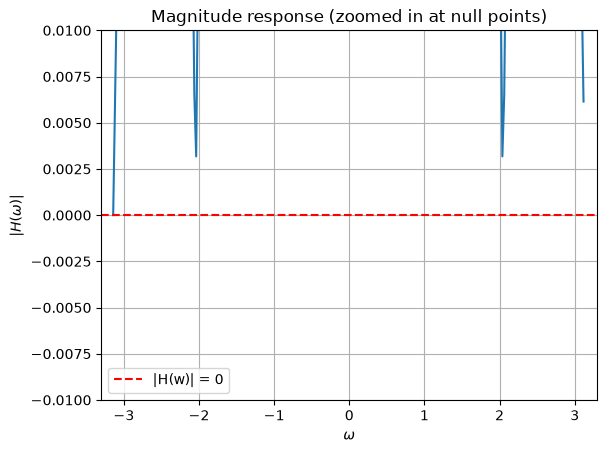

Therefore, the Null points are: 
    -> ±3.141592653589793 rad/sample
    -> ±2.0371264863121317 rad/sample


In [9]:

plt.plot(w, abs(H))
plt.xlabel('$\\omega$')
plt.ylabel('$|H(\\omega)|$')
plt.axhline(y = 0, linestyle='--', color='red', label = "|H(w)| = 0")
plt.ylim(-0.01, 0.01)
plt.xlim(-3.3, 3.3)
plt.title("Magnitude response (zoomed in at null points)")
plt.grid(True)
plt.legend()
plt.show()


null_points = []
for i in range(len(H)):
    if abs(H[i]) < 0.01 and w[i] <= 0:
        if abs(H[i]) < abs(H[i-1]) and abs(H[i]) < abs(H[(i+1) % len(H)]):
            null_points.append(abs(w[i]))

print("Therefore, the Null points are: ")

for point in null_points:
    print(f"    -> \u00b1{point} rad/sample")


### d)

The first thing I notice about the phase response is its exhibition of odd symmetry about the origin. 

Furthermore, the phase response is of the linear type, with a constant negative slope. This is indicative to all frequency components of the signal experiencing the same time delay.

Additionally, discontinuities can be observed. The discontinuities of $\pi$ radiance match accordingly with the null points, indicating the reason being sign reveral. The other, larger discontinuities of $2\pi$ radians are due to phase wrapping given the use of np.angle() which represents phases within the range $-\pi$ to $+\pi$.

# Task 6 

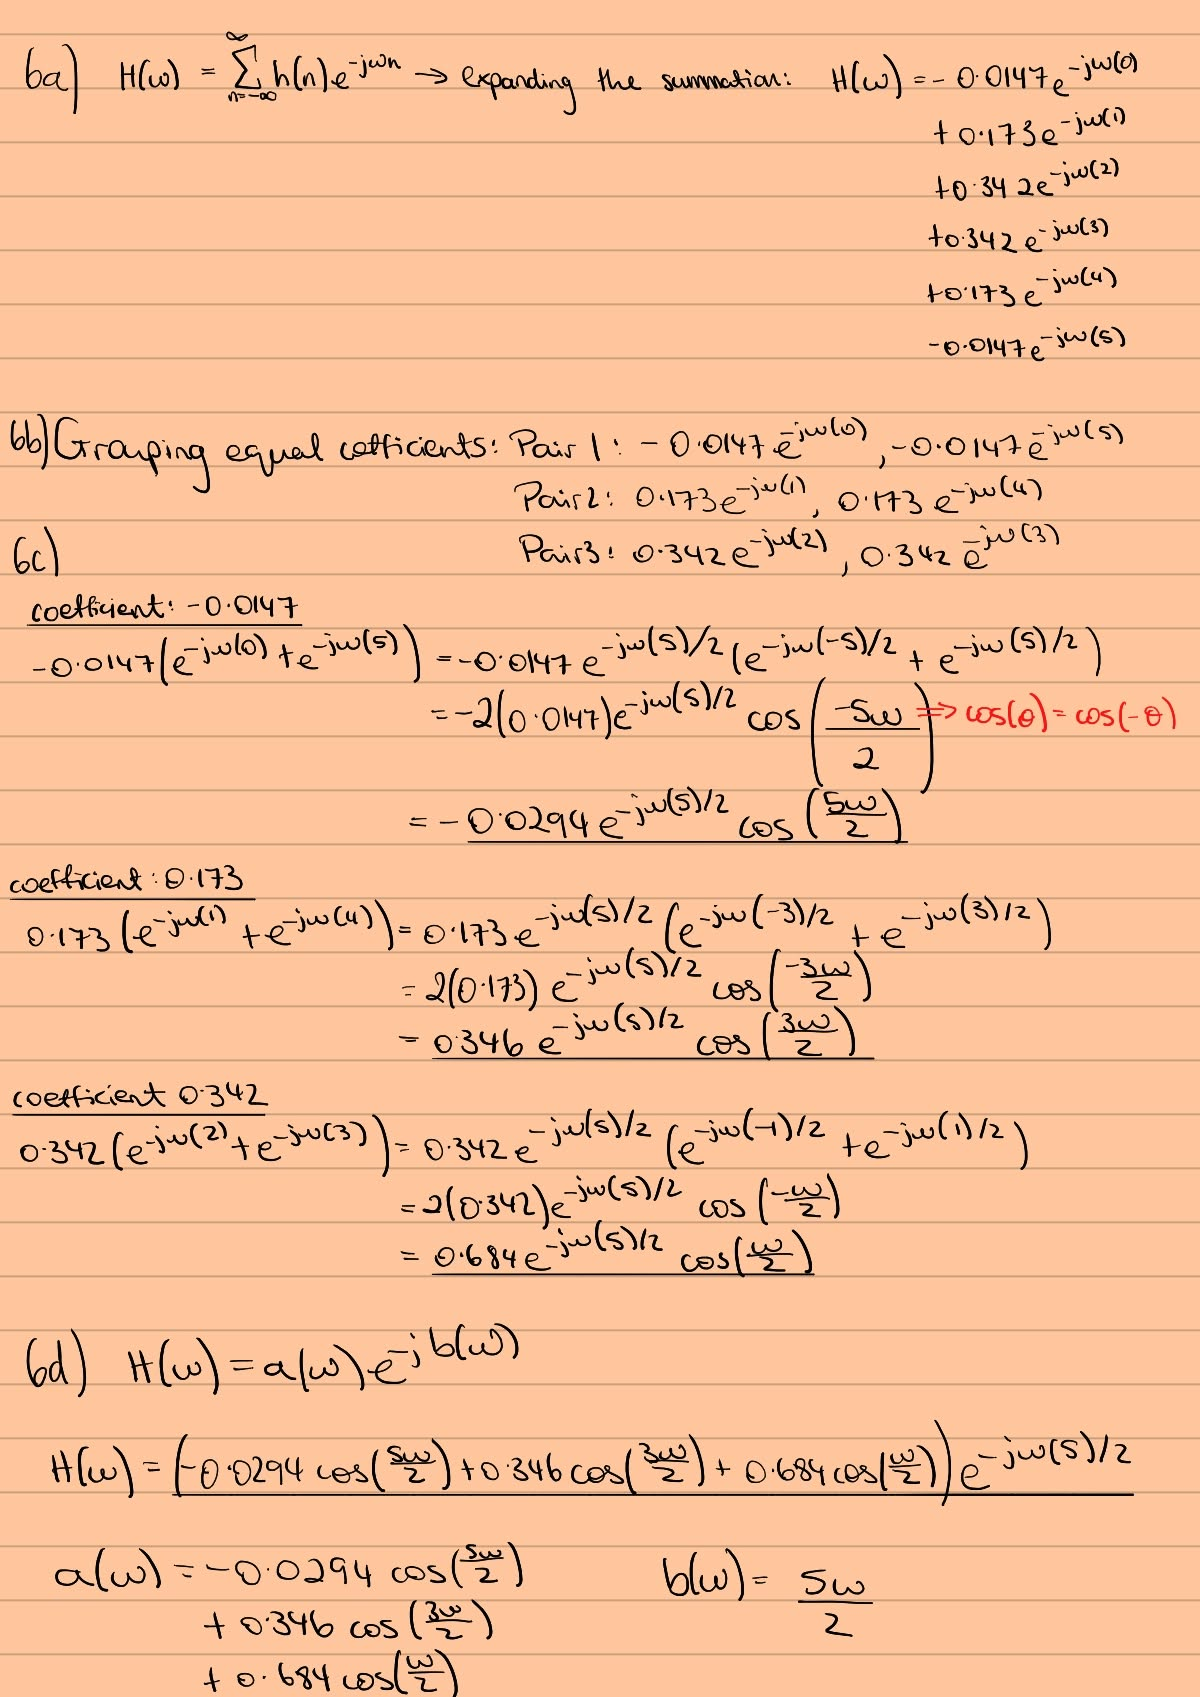

# Task 7 

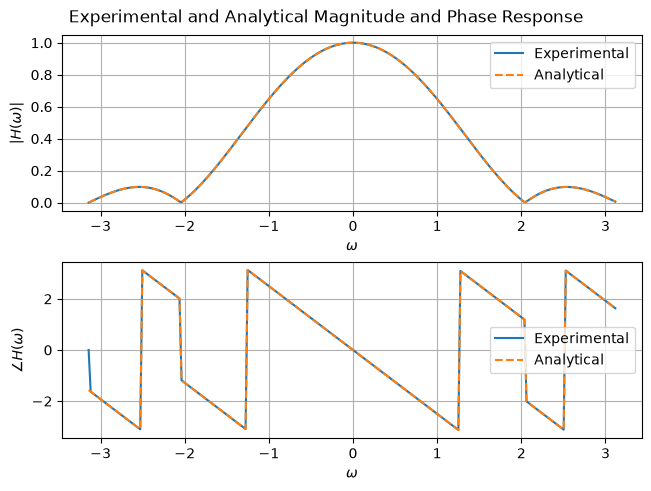

In [10]:
a = -0.0294 * np.cos(5*w/2) + 0.346 * np.cos(3*w/2) + 0.684 * np.cos(w/2)
b = 5*w/2
H_analytical = a * np.exp(-1j*b)

fig, ax = plt.subplots(2, 1, constrained_layout=True)

# magnitude resp
ax[0].plot(w, abs(H), label = "Experimental")
ax[0].plot(w, abs(H_analytical), '--', label ="Analytical")
ax[0].set_xlabel('$\\omega$')
ax[0].set_ylabel('$|H(\\omega)|$')
ax[0].grid(True)
ax[0].legend()

# phase resp
ax[1].plot(w, np.angle(H), label = "Experimental")
ax[1].plot(w, np.angle(H_analytical), '--', label= "Analytical")
ax[1].set_xlabel('$\\omega$')
ax[1].set_ylabel('$\\angle H(\\omega)$')
ax[1].grid(True)
ax[1].legend()

fig.suptitle('Experimental and Analytical Magnitude and Phase Response')

plt.show()


The Magnitude and Phase responses are practically identical for both the analytically and experimentally obtained $H(\omega)$. 

However, there is a small difference towards the left-most side of the Phase Response graph (at $\omega = -\pi$); the experimentally obtained $H(\omega)$ has a phase of $0$ radians, while the analytically obtained $H(\omega)$ has a phase of approximately $-1.5$ radians.

Since $\omega = -\pi$ corresponds to a null point, the phase is undefined. The difference between the two would likely be due to floating-point rounding errors. This can be checked as done below:

In [11]:
print("Experimental H:", H[0])
print("Experimental phase:", np.angle(H[0]))

print("Analytical H:", H_analytical[0])
print("Analytical phase:", np.angle(H_analytical[0]))

Experimental H: -0j
Experimental phase: -0.0
Analytical H: (-9.39224563891988e-33-3.0677402318641185e-17j)
Analytical phase: -1.570796326794897


The above confirms that although the analytical and experimental frequency responses are essentially identical, floating-point rounding errors can result in noticeable phase differences at sampled frequencies where the magnitude should be exactly zero.

Similar differences could have occurred at the other null points had their exact frequencies been sampled. However, as mentioned in task 5, these frequencies were not sampled exactly due to the limited frequency resolution of the 256-point DFT.

# Task 8 

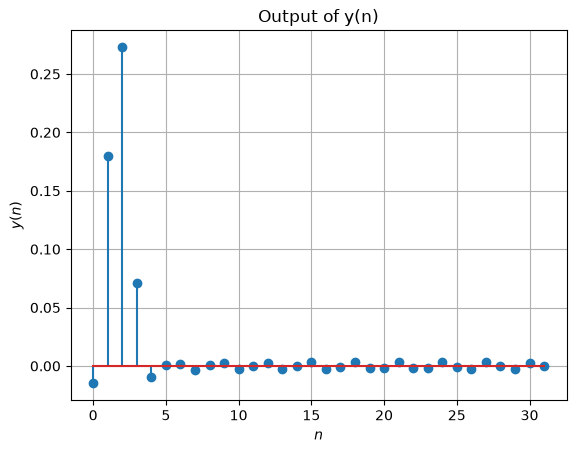

In [12]:
w0 = min(null_points)
x = np.cos(np.arange(32) * w0)

y = filter(x)

fig, ax = plt.subplots()
n = np.arange(len(y))
ax.stem(n, y)
ax.set_xlabel('$n$')
ax.set_ylabel('$y(n)$')
plt.grid()
plt.title("Output of y(n)")
plt.show()



One can note the transient that occurs in the beginning for n < 5.  At an exact null frequency, the products of the impulse response coefficients and their corresponding sinusoidal input samples add up to zero. Since for $n < 5$, some of the previous input samples are still zero, the weighted sum does not yet add up to zero as required for complete attenuation, resulting in the initial transient.


Additionally, one can see that the filter has an output of very close to zero after n >= 5. This is as expected as the frequency of the sinusoid corresponds to one of the null points of the filter; meaning it almost completely rejects a sinusoid at that particular frequency. 

The reason it does not fully reject the sinusoid is that the limited frequency resolution of the DFT results in an approximate null frequency being selected. Consequently, the products of the impulse response coefficients and their corresponding sinusoidal input samples add up to a value very close to, but not exactly, zero.

# Task 9 

### Task 9.1

In [13]:
h_new = np.array([-0.0147, -0.173, 0.342, -0.342, 0.173, 0.0147])
def filter_new(x):
    # set y to have the same length and type as x 
    y = np.zeros_like(x, dtype = float)

    # iterate overall all input samples
    for n in range(len(x)): # x array is in memory 
        # calculate y_n and store it in y[n]
        y_n = 0
        for k in range(6):
            if (n-k) < 0: # dont try access beyond what x holds
                y_n += 0
            elif (n-k) >= 0:
                y_n += h_new[k] * x[n-k]

        y[n] = y_n

    return y


### Task 9.2

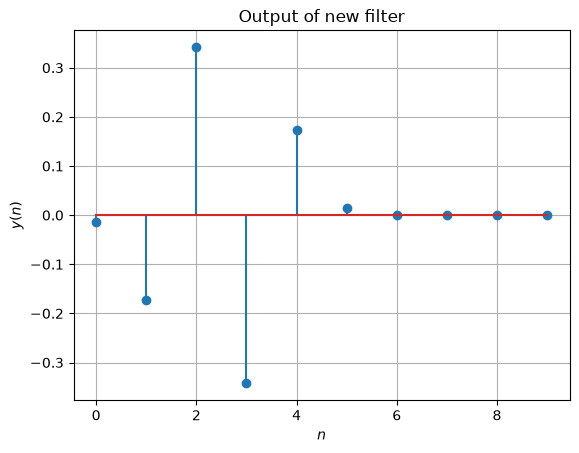

In [ ]:
# a
x_new = np.zeros(10)
x_new[0] = 1
# b
y_new = filter_new(x_new)
# c
fig, ax = plt.subplots()
n = np.arange(len(y_new))
ax.stem(n, y_new)
ax.set_xlabel('$n$')
ax.set_ylabel('$y(n)$')
plt.grid()
plt.title("Output of new filter")
plt.show()

### Task 9.3

In [15]:
for n in range(len(h_new)) :
    if y_new[n] == h_new[n]:
        print ("h(n) and y(n) match for n = ", n)
    elif y_new[n] != h_new[n]:
        print ("h(n) and y(n) do not match for n = ",n)

for n in range(len(h_new), len(y_new)):
    if y_new[n] == 0:
        print("y(n) is zero for n =", n)
    elif y_new[n] != 0:
        print("y(n) is not zero for n =", n)

h(n) and y(n) match for n =  0
h(n) and y(n) match for n =  1
h(n) and y(n) match for n =  2
h(n) and y(n) match for n =  3
h(n) and y(n) match for n =  4
h(n) and y(n) match for n =  5
y(n) is zero for n = 6
y(n) is zero for n = 7
y(n) is zero for n = 8
y(n) is zero for n = 9


As seen above, the output y(n) of the new filter when the input is the unit impulse x(n) is equal to h(n)

### Task 9.4

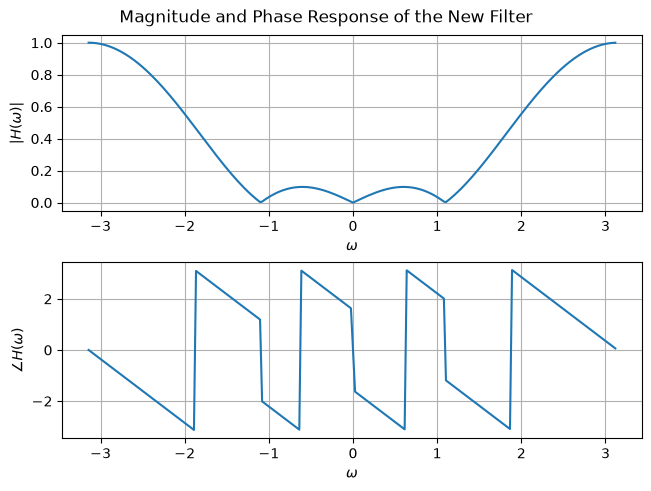

In [16]:
H_new = fft(h_new, 256)
w_new = fftfreq(256) * 2 * np.pi

H_new = fftshift(H_new)
w_new = fftshift(w_new)

fig, ax = plt.subplots(2, 1, constrained_layout=True)

ax[0].plot(w_new, abs(H_new))
ax[0].set_xlabel('$\\omega$')
ax[0].set_ylabel('$|H(\\omega)|$')
ax[0].grid(True)

ax[1].plot(w_new, np.angle(H_new))
ax[1].set_xlabel('$\\omega$')
ax[1].set_ylabel('$\\angle H(\\omega)$')
ax[1].grid(True)

fig.suptitle("Magnitude and Phase Response of the New Filter")

plt.show()

### Task 9.5

# Task 10